# 04 · Linear algebra, probability and calculus

**CSE273 Unit IV.** Scalars, vectors, matrices and tensors; eigenvalues and eigenvectors; random variables, distributions, statistical measures and the kinds of probability; Bayes' theorem and likelihood; functions, partial derivatives, the gradient and the chain rule.

Each idea is computed on the irrigation data and checked against a library or a numerical answer, so the maths is never just a formula on a page.

In [1]:
try:
    import groundwork
except ImportError:  # running on Kaggle
    %pip install -q git+https://github.com/LuShadowX/Groundwork
    import groundwork

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from groundwork import data, plotting
from groundwork.stats import numerical_grad
plotting.setup()

df = data.load()
s = data.sample(20_000, seed=4)

## 1. Linear algebra fundamentals

### 1.1 Data structures: scalars, vectors, matrices, tensors

A dataset *is* linear algebra: one field is a **vector** of features, the whole table is a **matrix** (rows = fields, columns = features), and a stack of such matrices (for example one per region) is a 3-D **tensor**.

In [2]:
scalar = df.loc[0, "Temperature_C"]
vector = df.loc[0, data.NUMERIC].to_numpy(dtype=float)
matrix = s[data.NUMERIC].to_numpy()
regions = sorted(df["Region"].unique())
tensor = np.stack([df.loc[df.Region == r, data.NUMERIC].iloc[:1000].to_numpy() for r in regions])
for name, obj in [("scalar", scalar), ("vector", vector), ("matrix", matrix), ("tensor", tensor)]:
    print(f"{name:7} ndim={np.ndim(obj)}  shape={np.shape(obj)}")

scalar  ndim=0  shape=()
vector  ndim=1  shape=(11,)
matrix  ndim=2  shape=(20000, 11)
tensor  ndim=3  shape=(5, 1000, 11)


The operations that matter in ML: a **dot product** (a weighted sum, which is what a linear model computes), the **norm** (length, used in regularisation and distances), **matrix–vector products** (a whole layer or a whole batch of predictions at once) and the **transpose**.

In [3]:
z = (matrix - matrix.mean(0)) / matrix.std(0)
w = pd.Series(0.0, index=data.NUMERIC)   # a hand-made "dryness" score
w[["Soil_Moisture", "Temperature_C", "Rainfall_mm", "Wind_Speed_kmh"]] = [-0.9, 0.5, -0.2, 0.5]
w = w.to_numpy()
print("dot product, one field:   ", round(z[0] @ w, 3))
print("matrix-vector, all fields:", (z @ w).shape)
print("L2 norm of w:", round(np.linalg.norm(w), 3), "| L1 norm:", round(np.linalg.norm(w, 1), 3))
print("covariance as a matrix product equals np.cov:",
      np.allclose(z.T @ z / (len(z) - 1), np.cov(z, rowvar=False)))

score = z @ w
need = s[data.TARGET].cat.codes
print("mean dryness score by class:", pd.Series(score).groupby(need.to_numpy()).mean().round(2).to_dict())

dot product, one field:    -0.773
matrix-vector, all fields: (20000,)
L2 norm of w: 1.162 | L1 norm: 2.1
covariance as a matrix product equals np.cov: True
mean dryness score by class: {0: -0.55, 1: 0.67, 2: 2.03}


A single dot product with hand-picked weights already ranks the classes in the right order (Low < Medium < High). Learning *good* weights automatically is what the optimisers in notebook 05 do.

### 1.2 Eigenvalues and eigenvectors

For a square matrix *A*, an eigenvector *v* only gets scaled, not turned: *Av = λv*. For a covariance matrix, the eigenvectors are the directions of greatest spread and the eigenvalues are the variance along them. That is exactly what PCA uses (CSE274).

First a 2×2 example drawn as a picture, then power iteration written from scratch and checked against `np.linalg.eigh`.

eigenvalues [1.382 3.618]
A v = [ 0.72654253 -1.1755705 ]  ≈  λ v = [ 0.72654253 -1.1755705 ]
A v = [-3.07768354 -1.90211303]  ≈  λ v = [-3.07768354 -1.90211303]


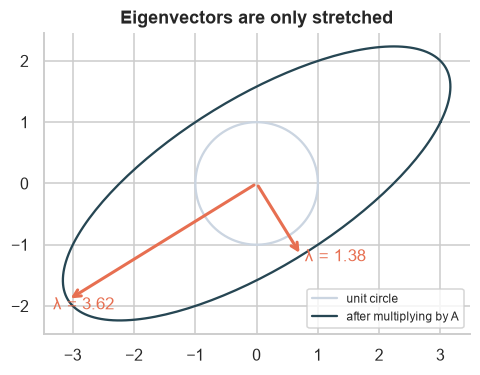

In [4]:
A = np.array([[3.0, 1.0], [1.0, 2.0]])
vals, vecs = np.linalg.eigh(A)
print("eigenvalues", vals.round(4))
for lam, v in zip(vals, vecs.T):
    print(f"A v = {A @ v}  ≈  λ v = {lam * v}")

fig, ax = plt.subplots(figsize=(5, 5))
theta = np.linspace(0, 2 * np.pi, 200)
circle = np.stack([np.cos(theta), np.sin(theta)])
ax.plot(*circle, color="#cbd5e1", label="unit circle")
ax.plot(*(A @ circle), color=plotting.ACCENT, label="after multiplying by A")
for lam, v in zip(vals, vecs.T):
    ax.annotate("", xy=lam * v, xytext=(0, 0), arrowprops={"arrowstyle": "->", "color": "#e76f51", "lw": 2})
    ax.text(*(lam * v * 1.08), f"λ = {lam:.2f}", color="#e76f51")
ax.set_aspect("equal")
ax.legend(loc="lower right", fontsize=8)
ax.set_title("Eigenvectors are only stretched")
plotting.save("g04-eigen")
plt.show()

In [5]:
def power_iteration(M, steps=500, seed=0):
    v = np.random.default_rng(seed).normal(size=M.shape[0])
    for _ in range(steps):
        v = M @ v
        v /= np.linalg.norm(v)
    return v @ M @ v, v

C = np.cov(z, rowvar=False)
lam_pi, v_pi = power_iteration(C)
lam_np, v_np = np.linalg.eigh(C)
print("power iteration  λ =", round(lam_pi, 6))
print("np.linalg.eigh   λ =", round(lam_np[-1], 6))
print("same direction (|cos| ≈ 1):", round(abs(v_pi @ v_np[:, -1]), 6))
print("all eigenvalues:", lam_np[::-1].round(3))

power iteration  λ = 1.107249
np.linalg.eigh   λ = 1.107249
same direction (|cos| ≈ 1): 1.0
all eigenvalues: [1.107 1.043 1.031 1.015 1.011 0.999 0.988 0.969 0.966 0.946 0.925]


The eigenvalues of the standardised features are all close to 1. That matches the EDA finding that the features are independent: there is no direction of extra spread, so PCA would not compress this dataset much. (CSE274 tries it anyway and confirms it.)

## 2. Probability foundations

### 2.1 Random variables
A random variable maps each outcome to a number. *X* = temperature of a randomly chosen field is **continuous**; *Y* = its irrigation level (0, 1, 2) is **discrete**.

### 2.2 Probability distributions
A discrete variable has a probability mass function (PMF); a continuous one has a density (PDF), whose area over an interval is a probability. Fitting standard distributions to the data:

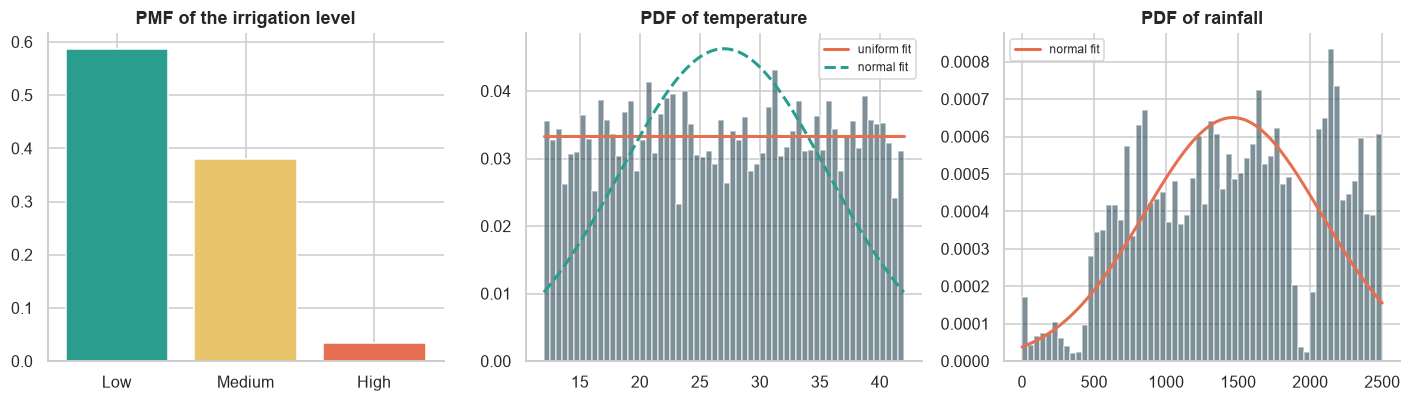

P(25 °C < temperature < 30 °C): data 0.1573 | uniform model 0.1667


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))

pmf = df[data.TARGET].value_counts(normalize=True)[data.CLASSES]
axes[0].bar(pmf.index, pmf.values, color=[plotting.CLASS_COLORS[c] for c in pmf.index])
axes[0].set_title("PMF of the irrigation level")

t = df["Temperature_C"]
grid = np.linspace(t.min(), t.max(), 200)
axes[1].hist(t, bins=60, density=True, alpha=0.6, color=plotting.ACCENT)
axes[1].plot(grid, stats.uniform.pdf(grid, t.min(), t.max() - t.min()), lw=2, color="#e76f51", label="uniform fit")
axes[1].plot(grid, stats.norm.pdf(grid, t.mean(), t.std()), lw=2, ls="--", color="#2a9d8f", label="normal fit")
axes[1].set_title("PDF of temperature")
axes[1].legend(fontsize=8)

r = df["Rainfall_mm"]
grid = np.linspace(r.min(), r.max(), 200)
axes[2].hist(r, bins=60, density=True, alpha=0.6, color=plotting.ACCENT)
axes[2].plot(grid, stats.norm.pdf(grid, r.mean(), r.std()), lw=2, color="#e76f51", label="normal fit")
axes[2].set_title("PDF of rainfall")
axes[2].legend(fontsize=8)
fig.tight_layout()
plotting.save("g04-distributions")
plt.show()

print("P(25 °C < temperature < 30 °C): data", round(t.between(25, 30).mean(), 4),
      "| uniform model", round(stats.uniform.cdf(30, t.min(), t.max() - t.min()) - stats.uniform.cdf(25, t.min(), t.max() - t.min()), 4))

Temperature is close to **uniform** between 12 and 42 °C, so a normal model would be wrong in the tails. Picking the right distribution matters: the uniform model gets the probability of an interval within a percentage point.

### 2.3 Statistical measures

In [7]:
x = df["Soil_Moisture"]
pd.Series({
    "mean": x.mean(), "median": x.median(), "mode (1 dp)": x.round(1).mode()[0],
    "variance": x.var(), "standard deviation": x.std(), "range": x.max() - x.min(),
    "IQR": x.quantile(0.75) - x.quantile(0.25), "covariance with temperature": x.cov(df["Temperature_C"]),
    "correlation with temperature": x.corr(df["Temperature_C"]),
}).round(4).to_frame("soil moisture")

,soil moisture
mean,37.3045
median,37.7500
mode (1 dp),52.4000
variance,268.2088
standard deviation,16.3771
range,56.9900
IQR,27.9300
covariance with temperature,-5.3513
correlation with temperature,-0.0379


### 2.4 Types of probability
From a contingency table of mulching against irrigation need:
- **joint** P(A and B): both happen,
- **marginal** P(A): one variable, summed over the other,
- **conditional** P(A | B) = P(A and B) / P(B).

In [8]:
joint = pd.crosstab(df["Mulching_Used"], df[data.TARGET], normalize=True)
print("joint P(mulching, need):\n", joint.round(4), "\n")
p_high = joint["High"].sum()
p_no_mulch = joint.loc["No"].sum()
p_high_and_no = joint.loc["No", "High"]
print(f"marginal     P(High)            = {p_high:.4f}")
print(f"marginal     P(no mulch)        = {p_no_mulch:.4f}")
print(f"joint        P(High, no mulch)  = {p_high_and_no:.4f}")
print(f"conditional  P(High | no mulch) = {p_high_and_no / p_no_mulch:.4f}")
print(f"conditional  P(High | mulch)    = {joint.loc['Yes', 'High'] / joint.loc['Yes'].sum():.4f}")
print(f"independent? P(High)·P(no mulch) = {p_high * p_no_mulch:.4f} vs joint {p_high_and_no:.4f}")

joint P(mulching, need):
 Irrigation_Need     Low  Medium    High
Mulching_Used                          
No               0.2235  0.2494  0.0294
Yes              0.3636  0.1301  0.0039 

marginal     P(High)            = 0.0333
marginal     P(no mulch)        = 0.5023
joint        P(High, no mulch)  = 0.0294
conditional  P(High | no mulch) = 0.0585
conditional  P(High | mulch)    = 0.0079
independent? P(High)·P(no mulch) = 0.0168 vs joint 0.0294


The joint probability is not the product of the marginals, so mulching and irrigation need are **dependent**: knowing a field is unmulched makes High about seven times more likely.

## 3. Bayes' theorem and inference

### 3.1 The theorem

P(H | E) = P(E | H) · P(H) / P(E)

Question: a field is **dry** (soil moisture < 20%). How likely is it to need High irrigation? The answer is built from three pieces, then checked by counting directly.

In [9]:
dry = df["Soil_Moisture"] < 20
high = df[data.TARGET] == "High"
prior = high.mean()                       # P(High)
likelihood = dry[high].mean()             # P(dry | High)
evidence = dry.mean()                     # P(dry)
posterior = likelihood * prior / evidence
print(f"prior       P(High)         = {prior:.4f}")
print(f"likelihood  P(dry | High)   = {likelihood:.4f}")
print(f"evidence    P(dry)          = {evidence:.4f}")
print(f"posterior   P(High | dry)   = {posterior:.4f}   (Bayes)")
print(f"counted     P(High | dry)   = {high[dry].mean():.4f}   (direct)")

prior       P(High)         = 0.0333
likelihood  P(dry | High)   = 0.6444
evidence    P(dry)          = 0.1909
posterior   P(High | dry)   = 0.1125   (Bayes)
counted     P(High | dry)   = 0.1125   (direct)


One piece of evidence updates the belief from 3.3% to 11%, and Bayes' formula gives exactly the same number as counting. Adding more evidence (hot, unmulched, in the flowering stage) keeps updating it. That is how a Naive Bayes classifier works, which multiplies one likelihood per feature:

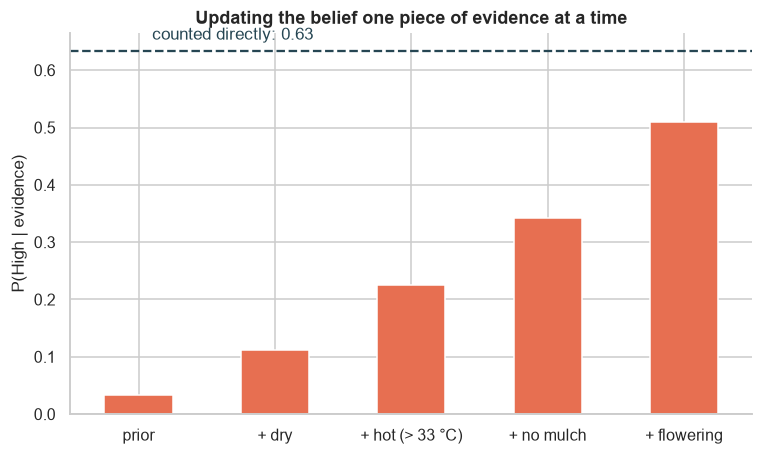

prior              0.033
+ dry              0.113
+ hot (> 33 °C)    0.225
+ no mulch         0.343
+ flowering        0.510
dtype: float64

In [10]:
def posterior_high(mask_list):
    p = prior
    for m in mask_list:
        p_e_h = m[high].mean()
        p_e_not = m[~high].mean()
        p = p * p_e_h / (p * p_e_h + (1 - p) * p_e_not)   # Bayes, one piece of evidence at a time
    return p

steps = {"prior": [], "+ dry": [dry], "+ hot (> 33 °C)": [dry, df["Temperature_C"] > 33],
         "+ no mulch": [dry, df["Temperature_C"] > 33, df["Mulching_Used"] == "No"],
         "+ flowering": [dry, df["Temperature_C"] > 33, df["Mulching_Used"] == "No", df["Crop_Growth_Stage"] == "Flowering"]}
seq = pd.Series({k: posterior_high(v) for k, v in steps.items()})
both = dry & (df["Temperature_C"] > 33) & (df["Mulching_Used"] == "No") & (df["Crop_Growth_Stage"] == "Flowering")
ax = seq.plot.bar(rot=0, color=plotting.CLASS_COLORS["High"])
ax.axhline(high[both].mean(), ls="--", color=plotting.ACCENT)
ax.text(0.1, high[both].mean() + 0.02, f"counted directly: {high[both].mean():.2f}", color=plotting.ACCENT)
ax.set(ylabel="P(High | evidence)", title="Updating the belief one piece of evidence at a time")
plotting.save("g04-bayes")
plt.show()
seq.round(3)

The sequential update assumes the pieces of evidence are independent given the class (the "naive" assumption). The dashed line is the honest answer counted from the data; the gap between the two shows how far that assumption is from the truth for these features.

### 3.2 Likelihood vs probability
**Probability** fixes the parameters and asks about data: if moisture ~ N(μ = 37, σ = 16), how likely is a reading of 20? **Likelihood** fixes the data and asks about parameters: given the readings we saw, how plausible is each μ? Same formula, read in opposite directions. Maximising the likelihood is notebook 05.

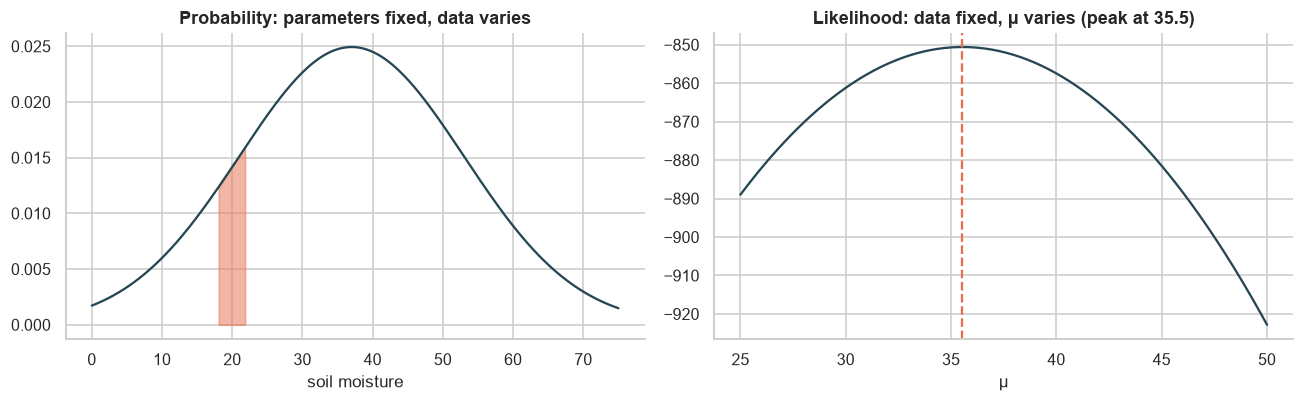

P(18 < moisture < 22 | μ=37, σ=16) = 0.0567
sample mean = 35.54 = the μ with the highest likelihood


In [11]:
sample_x = df["Soil_Moisture"].sample(200, random_state=0).to_numpy()
mus = np.linspace(25, 50, 300)
loglik = [stats.norm.logpdf(sample_x, m, sample_x.std()).sum() for m in mus]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
grid = np.linspace(0, 75, 300)
axes[0].plot(grid, stats.norm.pdf(grid, 37, 16), color=plotting.ACCENT)
axes[0].fill_between(grid, stats.norm.pdf(grid, 37, 16), where=(grid > 18) & (grid < 22), color="#e76f51", alpha=0.5)
axes[0].set(title="Probability: parameters fixed, data varies", xlabel="soil moisture")
axes[1].plot(mus, loglik, color=plotting.ACCENT)
axes[1].axvline(mus[np.argmax(loglik)], ls="--", color="#e76f51")
axes[1].set(title=f"Likelihood: data fixed, μ varies (peak at {mus[np.argmax(loglik)]:.1f})", xlabel="μ")
fig.tight_layout()
plotting.save("g04-likelihood")
plt.show()
print("P(18 < moisture < 22 | μ=37, σ=16) =", round(stats.norm.cdf(22, 37, 16) - stats.norm.cdf(18, 37, 16), 4))
print("sample mean =", round(sample_x.mean(), 2), "= the μ with the highest likelihood")

## 4. Calculus for machine learning

### 4.1 Functions
A model is a function from features to a prediction; a loss is a function from parameters to a number. For one weight *w* and the dryness feature, the logistic loss *L(w)* is smooth and bowl-shaped, which is why gradient descent can find its minimum.

### 4.2 Partial derivatives and 4.3 the gradient
With many parameters, each partial derivative ∂L/∂wᵢ measures the slope along one axis, holding the others still. Together they form the gradient ∇L, which points uphill. The gradient of the logistic loss is derived by hand, *∇L = Xᵀ(σ(Xw) − y) / n*, and checked against finite differences:

In [12]:
Xh = np.column_stack([np.ones(len(z)), z])           # bias + 11 standardised features
yh = (s[data.TARGET] == "High").to_numpy().astype(float)

def sigmoid(u):
    return 1 / (1 + np.exp(-u))

def loss(w):
    p = sigmoid(Xh @ w)
    return -np.mean(yh * np.log(p + 1e-12) + (1 - yh) * np.log(1 - p + 1e-12))

def grad(w):
    return Xh.T @ (sigmoid(Xh @ w) - yh) / len(yh)

w0 = np.random.default_rng(0).normal(0, 0.1, Xh.shape[1])
g_hand, g_num = grad(w0), numerical_grad(loss, w0)
print("max |hand − numerical| =", f"{np.abs(g_hand - g_num).max():.2e}")
pd.DataFrame({"analytic": g_hand, "numerical": g_num}, index=["bias"] + data.NUMERIC).round(6)

max |hand − numerical| = 8.25e-12


,analytic,numerical
bias,0.469755,0.469755
Soil_pH,-0.007820,-0.007820
Soil_Moisture,0.057789,0.057789
Organic_Carbon,0.000499,0.000499
Electrical_Conductivity,-0.011414,-0.011414
Temperature_C,-0.022561,-0.022561
Humidity,0.031789,0.031789
Rainfall_mm,0.048268,0.048268
Sunlight_Hours,-0.016047,-0.016047
Wind_Speed_kmh,-0.057021,-0.057021


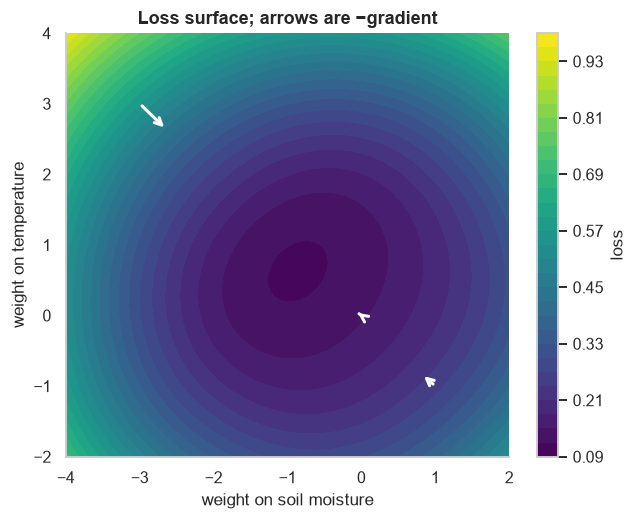

In [13]:
w1 = np.linspace(-4, 2, 120)
w2 = np.linspace(-2, 4, 120)
W1, W2 = np.meshgrid(w1, w2)
base = np.zeros(Xh.shape[1]); base[0] = -3.4
moist, temp = 1 + data.NUMERIC.index("Soil_Moisture"), 1 + data.NUMERIC.index("Temperature_C")
L = np.empty_like(W1)
for i in range(W1.shape[0]):
    for j in range(W1.shape[1]):
        wv = base.copy(); wv[moist] = W1[i, j]; wv[temp] = W2[i, j]
        L[i, j] = loss(wv)

fig, ax = plt.subplots(figsize=(6.5, 5))
cs = ax.contourf(W1, W2, L, levels=30, cmap="viridis")
fig.colorbar(cs, label="loss")
for a, b in [(-3, 3), (0, 0), (1, -1)]:
    wv = base.copy(); wv[moist], wv[temp] = a, b
    g = grad(wv)
    ax.annotate("", xy=(a - 2 * g[moist], b - 2 * g[temp]), xytext=(a, b), arrowprops={"arrowstyle": "->", "color": "white", "lw": 2})
ax.set(xlabel="weight on soil moisture", ylabel="weight on temperature", title="Loss surface; arrows are −gradient")
plotting.save("g04-gradient")
plt.show()

The arrows (negative gradient) point down the slope towards the low-loss corner: a negative weight on moisture and a positive weight on temperature, which matches the EDA.

### 4.4 The chain rule
A model is a chain of functions: *u = Xw* → *p = σ(u)* → *L(p)*. The chain rule multiplies the local derivatives: dL/dw = dL/dp · dp/du · du/dw. With σ′(u) = σ(u)(1 − σ(u)), the pieces collapse to the simple gradient above. Back-propagation in neural networks is this same rule applied layer by layer. Here it is done step by step for one field and one weight:

In [14]:
i, k = 0, moist
u = Xh[i] @ w0
p = sigmoid(u)
dL_dp = -(yh[i] / p) + (1 - yh[i]) / (1 - p)
dp_du = p * (1 - p)
du_dw = Xh[i, k]
chain = dL_dp * dp_du * du_dw

def single_loss(wk):
    wv = w0.copy(); wv[k] = wk
    q = sigmoid(Xh[i] @ wv)
    return -(yh[i] * np.log(q) + (1 - yh[i]) * np.log(1 - q))

print(f"dL/dp = {dL_dp:.5f}   dp/du = {dp_du:.5f}   du/dw = {du_dw:.5f}")
print(f"chain rule product     = {chain:.6f}")
print(f"simplified (p − y)·x   = {(p - yh[i]) * du_dw:.6f}")
print(f"numerical derivative   = {numerical_grad(lambda v: single_loss(v[0]), np.array([w0[k]]))[0]:.6f}")

dL/dp = 1.90680   dp/du = 0.24940   du/dw = -0.27489
chain rule product     = -0.130726
simplified (p − y)·x   = -0.130726
numerical derivative   = -0.130726


| Syllabus topic | Where |
|---|---|
| Data structures (scalar → tensor) | 1.1 |
| Eigenvalues and eigenvectors | 1.2 (drawing, power iteration from scratch) |
| Random variables, distributions | 2.1, 2.2 |
| Statistical measures | 2.3 |
| Types of probability (joint, marginal, conditional) | 2.4 |
| Bayes' theorem, likelihood vs probability | 3.1, 3.2 |
| Functions, partial derivatives, gradient | 4.1–4.3 (hand gradient checked numerically) |
| Chain rule | 4.4 |